# **Ridge, Lasso & Elastic Net Regression — Practice Notebook**

Datasets: **Diamonds** and **Car Crashes** (from the Seaborn library)

For each dataset, you will build and compare three regularized regression models:
1. Ridge Regression
2. Lasso Regression
3. Elastic Net Regression

Write your code in the empty cells below each question.

## **Part A: Diamonds Dataset**

Target variable: `price`

**Q1.** Import the required libraries and load the `diamonds` dataset from Seaborn. Display the first 5 rows.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
df = sns.load_dataset("diamonds")
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


**Q2.** Check the shape of the dataset, data types, and confirm whether there are any missing values.

In [2]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

**Q3.** Identify the categorical columns in the dataset (e.g., `cut`, `color`, `clarity`) and encode them into numeric form.

In [3]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in ['cut', 'color', 'clarity']:
    df[col] = le.fit_transform(df[col])
print(df[['cut', 'color', 'clarity']].head())
df.info()

   cut  color  clarity
0    2      1        3
1    3      1        2
2    1      1        4
3    3      5        5
4    1      6        3
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  int64  
 2   color    53940 non-null  int64  
 3   clarity  53940 non-null  int64  
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(4)
memory usage: 4.1 MB


**Q4.** Define the independent variables `X` (all relevant feature columns) and the dependent variable `y` (`price`).

In [4]:
X = df[['carat','cut','color','clarity','depth','table','x','y','z']]
y = df[['price']]

**Q5.** Split the dataset into training and testing sets.

In [5]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

**Q6.** Scale the training and testing features appropriately.

In [6]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

### Ridge Regression — Diamonds

**Q7.** Build a Ridge Regression model and train it on the training data.

In [7]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled,y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


**Q8.** Predict `price` for the test set and calculate MAE, RMSE, and R² score.

In [8]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
y_pred_ridge = ridge.predict(X_test_scaled)
print("MAE:",mean_absolute_error(y_test,y_pred_ridge))
print("RMSE:",mean_squared_error(y_test,y_pred_ridge))
print("R2 Score:",r2_score(y_test,y_pred_ridge))

MAE: 860.6750938580977
RMSE: 1825728.6696759479
R2 Score: 0.8851513382550269


**Q9.** Print the model's coefficients.

In [9]:
ridge_coef = pd.Series(ridge.coef_,index=X.columns)
print(ridge_coef)

carat      5200.081500
cut          73.946643
color      -456.353444
clarity     493.850288
depth      -222.119292
table      -210.424093
x         -1306.871118
y            26.974964
z             8.116841
dtype: float64


### Lasso Regression — Diamonds

**Q10.** Build a Lasso Regression model and train it on the training data.

In [10]:
from sklearn.linear_model import Lasso
lasso = Lasso(alpha=0.1)
lasso.fit(X_train_scaled,y_train)

,alpha,0.1
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


**Q11.** Predict `price` for the test set and calculate MAE, RMSE, and R² score.

In [11]:
y_pred_lasso = lasso.predict(X_test_scaled)
print("MAE:",mean_absolute_error(y_test,y_pred_lasso))
print("RMSE:",mean_squared_error(y_test,y_pred_lasso))
print("R2 Score:",r2_score(y_test,y_pred_lasso))
r2 = r2_score(y_test,y_pred_lasso)
print("R2 Score:", r2)
print("Model Accuracy (%):", r2 * 100)

MAE: 860.6643744347587
RMSE: 1825748.749567263
R2 Score: 0.8851500751162682
R2 Score: 0.8851500751162682
Model Accuracy (%): 88.51500751162682


**Q12.** Print the model's coefficients. Identify if any coefficients became exactly zero.

In [12]:
lasso_coef = pd.Series(lasso.coef_,index=X.columns)
print(lasso_coef)

carat      5198.981162
cut          73.883475
color      -456.252533
clarity     493.803001
depth      -221.611918
table      -210.322926
x         -1300.686712
y            24.678863
z             5.150266
dtype: float64


### Elastic Net Regression — Diamonds

**Q13.** Build an Elastic Net Regression model and train it on the training data.

In [13]:
from sklearn.linear_model import ElasticNet
elastic = ElasticNet(alpha=0.1)
elastic.fit(X_train_scaled,y_train)

,alpha,0.1
,l1_ratio,0.5
,fit_intercept,True
,precompute,False
,max_iter,1000
,copy_X,True
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


**Q14.** Predict `price` for the test set and calculate MAE, RMSE, and R² score.

In [14]:
y_pred_elastic = elastic.predict(X_test_scaled)
print("MAE:",mean_absolute_error(y_test,y_pred_elastic))
print("RMSE:",mean_squared_error(y_test,y_pred_elastic))
print("R2 Score:",r2_score(y_test,y_pred_elastic))
r2 = r2_score(y_test,y_pred_elastic)
print("R2 Score:", r2)
print("Model Accuracy (%):", r2 * 100)

MAE: 1003.6795578410158
RMSE: 2090528.5050467995
R2 Score: 0.8684939305976068
R2 Score: 0.8684939305976068
Model Accuracy (%): 86.84939305976069


**Q15.** Print the model's coefficients.

In [15]:
elastic_coef = pd.Series(elastic.coef_,index=X.columns)
print(elastic_coef)

carat      2754.030191
cut          78.870997
color      -362.065559
clarity     480.751748
depth      -105.362871
table      -172.973383
x           544.879310
y           277.890727
z           245.494614
dtype: float64


**Q16.** Compare the coefficients of all three models (Ridge, Lasso, Elastic Net) side by side in a single DataFrame, and plot them on a bar chart.

               Ridge        Lasso   ElasticNet
carat    5200.081500  5198.981162  2754.030191
cut        73.946643    73.883475    78.870997
color    -456.353444  -456.252533  -362.065559
clarity   493.850288   493.803001   480.751748
depth    -222.119292  -221.611918  -105.362871
table    -210.424093  -210.322926  -172.973383
x       -1306.871118 -1300.686712   544.879310
y          26.974964    24.678863   277.890727
z           8.116841     5.150266   245.494614


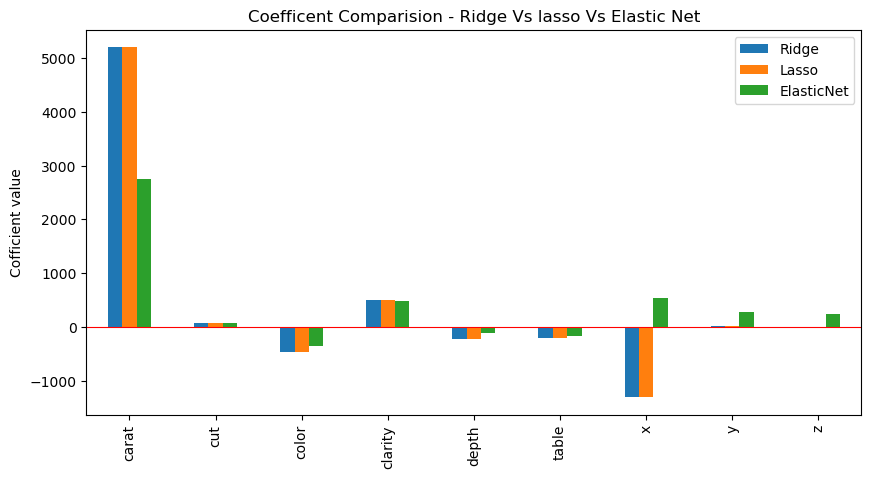

In [16]:
import matplotlib.pyplot as plt
comparison_df = pd.DataFrame({
    "Ridge":ridge_coef,
    "Lasso":lasso_coef,
    "ElasticNet":elastic_coef
})
print(comparison_df)
comparison_df.plot(kind='bar',figsize=(10,5))
plt.title("Coefficent Comparision - Ridge Vs lasso Vs Elastic Net")
plt.ylabel("Cofficient value")
plt.axhline(0,color='red',linewidth=0.8)
plt.show()

**Q17.** Compare the R² scores of the three models. Which model performed best on the Diamonds dataset?

In [17]:
print("Ridge R2:",r2_score(y_test,y_pred_ridge))
print("Lasso R2:",r2_score(y_test,y_pred_lasso))
print("Elastic R2:",r2_score(y_test,y_pred_elastic))

Ridge R2: 0.8851513382550269
Lasso R2: 0.8851500751162682
Elastic R2: 0.8684939305976068


## **Part B: Car Crashes Dataset**

Target variable: `total`

**Q18.** Load the `car_crashes` dataset from Seaborn. Display the first 5 rows.

In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
df = sns.load_dataset("car_crashes")
df.head()

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,7.332,5.640,18.048,15.040,784.55,145.08,AL
1,18.1,7.421,4.525,16.290,17.014,1053.48,133.93,AK
2,18.6,6.510,5.208,15.624,17.856,899.47,110.35,AZ
3,22.4,4.032,5.824,21.056,21.280,827.34,142.39,AR
4,12.0,4.200,3.360,10.920,10.680,878.41,165.63,CA


**Q19.** Check the shape of the dataset, data types, and confirm whether there are any missing values.

In [19]:
df.dtypes
df.shape
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   total           51 non-null     float64
 1   speeding        51 non-null     float64
 2   alcohol         51 non-null     float64
 3   not_distracted  51 non-null     float64
 4   no_previous     51 non-null     float64
 5   ins_premium     51 non-null     float64
 6   ins_losses      51 non-null     float64
 7   abbrev          51 non-null     object 
dtypes: float64(7), object(1)
memory usage: 3.3+ KB


total             0
speeding          0
alcohol           0
not_distracted    0
no_previous       0
ins_premium       0
ins_losses        0
abbrev            0
dtype: int64

**Q20.** Identify and handle any non-numeric column(s) that should not be used directly as model inputs.

In [20]:
non_numeric_columns = df.select_dtypes(
    exclude="number"
).columns.tolist()
print("Non-numeric columns:", non_numeric_columns)
df = df.drop(columns=non_numeric_columns)
df.head()

Non-numeric columns: ['abbrev']


,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses
0,18.8,7.332,5.640,18.048,15.040,784.55,145.08
1,18.1,7.421,4.525,16.290,17.014,1053.48,133.93
2,18.6,6.510,5.208,15.624,17.856,899.47,110.35
3,22.4,4.032,5.824,21.056,21.280,827.34,142.39
4,12.0,4.200,3.360,10.920,10.680,878.41,165.63


**Q21.** Define the independent variables `X` (all relevant numeric feature columns) and the dependent variable `y` (`total`).

In [21]:
X = df[['speeding','alcohol','not_distracted','no_previous','ins_premium','ins_losses']]
y = df[['total']]

**Q22.** Split the dataset into training and testing sets.

In [22]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

**Q23.** Scale the training and testing features appropriately.

In [23]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

### Ridge Regression — Car Crashes

**Q24.** Build a Ridge Regression model and train it on the training data.

In [24]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled,y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


**Q25.** Predict `total` for the test set and calculate MAE, RMSE, and R² score.

In [25]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
y_pred_ridge = ridge.predict(X_test_scaled)
print("MAE:",mean_absolute_error(y_test,y_pred_ridge))
print("RMSE:",mean_squared_error(y_test,y_pred_ridge))
print("R2 Score:",r2_score(y_test,y_pred_ridge))

MAE: 1.7176711447342121
RMSE: 4.484515598118724
R2 Score: 0.7520442390000156


**Q26.** Print the model's coefficients.

In [26]:
ridge_coef = pd.Series(ridge.coef_,index=X.columns)
print(ridge_coef)

speeding          0.221816
alcohol           0.724939
not_distracted    0.952466
no_previous       2.185092
ins_premium      -0.365562
ins_losses        0.174332
dtype: float64


### Lasso Regression — Car Crashes

**Q27.** Build a Lasso Regression model and train it on the training data.

In [27]:
from sklearn.linear_model import Lasso
lasso = Lasso(alpha=0.1)
lasso.fit(X_train_scaled,y_train)

,alpha,0.1
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


**Q28.** Predict `total` for the test set and calculate MAE, RMSE, and R² score.

In [28]:
y_pred_lasso = lasso.predict(X_test_scaled)
print("MAE:",mean_absolute_error(y_test,y_pred_lasso))
print("RMSE:",mean_squared_error(y_test,y_pred_lasso))
print("R2 Score:",r2_score(y_test,y_pred_lasso))
r2 = r2_score(y_test,y_pred_lasso)
print("R2 Score:", r2)
print("Model Accuracy (%):", r2 * 100)

MAE: 1.6863374987945292
RMSE: 4.3739489428663285
R2 Score: 0.7581576393315546
R2 Score: 0.7581576393315546
Model Accuracy (%): 75.81576393315545


**Q29.** Print the model's coefficients. Identify if any coefficients became exactly zero.

In [29]:
lasso_coef = pd.Series(lasso.coef_,index=X.columns)
print(lasso_coef)

speeding          0.111352
alcohol           0.644625
not_distracted    0.864796
no_previous       2.374953
ins_premium      -0.182104
ins_losses        0.000000
dtype: float64


### Elastic Net Regression — Car Crashes

**Q30.** Build an Elastic Net Regression model and train it on the training data.

In [30]:
from sklearn.linear_model import ElasticNet
elastic = ElasticNet(alpha=0.1)
elastic.fit(X_train_scaled,y_train)

,alpha,0.1
,l1_ratio,0.5
,fit_intercept,True
,precompute,False
,max_iter,1000
,copy_X,True
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


**Q31.** Predict `total` for the test set and calculate MAE, RMSE, and R² score.

In [31]:
y_pred_elastic = elastic.predict(X_test_scaled)
print("MAE:",mean_absolute_error(y_test,y_pred_elastic))
print("RMSE:",mean_squared_error(y_test,y_pred_elastic))
print("R2 Score:",r2_score(y_test,y_pred_elastic))
r2 = r2_score(y_test,y_pred_elastic)
print("R2 Score:", r2)
print("Model Accuracy (%):", r2 * 100)

MAE: 1.7176620978170696
RMSE: 4.6224024801822905
R2 Score: 0.7444202613315403
R2 Score: 0.7444202613315403
Model Accuracy (%): 74.44202613315403


**Q32.** Print the model's coefficients.

In [32]:
elastic_coef = pd.Series(elastic.coef_,index=X.columns)
print(elastic_coef)

speeding          0.228503
alcohol           0.726976
not_distracted    1.014454
no_previous       2.043400
ins_premium      -0.236434
ins_losses        0.053946
dtype: float64


**Q33.** Compare the coefficients of all three models (Ridge, Lasso, Elastic Net) side by side in a single DataFrame, and plot them on a bar chart.

                   Ridge     Lasso  ElasticNet
speeding        0.221816  0.111352    0.228503
alcohol         0.724939  0.644625    0.726976
not_distracted  0.952466  0.864796    1.014454
no_previous     2.185092  2.374953    2.043400
ins_premium    -0.365562 -0.182104   -0.236434
ins_losses      0.174332  0.000000    0.053946


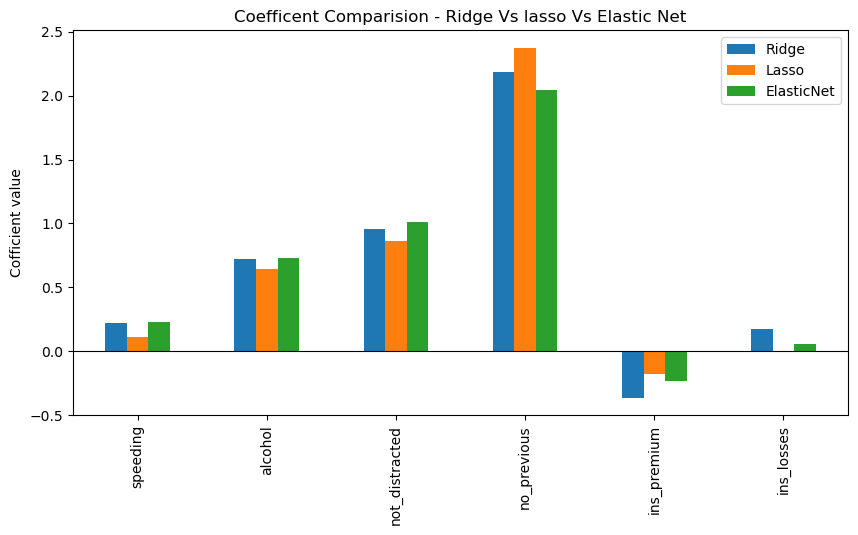

In [33]:
import matplotlib.pyplot as plt
comparison_df = pd.DataFrame({
    "Ridge":ridge_coef,
    "Lasso":lasso_coef,
    "ElasticNet":elastic_coef
})
print(comparison_df)
comparison_df.plot(kind='bar',figsize=(10,5))
plt.title("Coefficent Comparision - Ridge Vs lasso Vs Elastic Net")
plt.ylabel("Cofficient value")
plt.axhline(0,color='black',linewidth=0.8)
plt.show()

**Q34.** Compare the R² scores of the three models. Which model performed best on the Car Crashes dataset?

In [34]:
print("Ridge R2:",r2_score(y_test,y_pred_ridge))
print("Lasso R2:",r2_score(y_test,y_pred_lasso))
print("Elastic R2:",r2_score(y_test,y_pred_elastic))

Ridge R2: 0.7520442390000156
Lasso R2: 0.7581576393315546
Elastic R2: 0.7444202613315403


## **Final Comparison**

**Q35.** Summarize the R² scores of all six models (Ridge, Lasso, Elastic Net — for both Diamonds and Car Crashes) in a single table. Based on your results, in which situations did Lasso's feature-elimination behavior become most noticeable, and why might that be?

In [36]:
r2_ridge_diamonds = r2_score(y_test,y_pred_ridge)
r2_lasso_diamonds = r2_score(y_test,y_pred_lasso)
r2_elastic_diamonds = r2_score(y_test,y_pred_elastic)
r2_ridge_crashes = r2_score(y_test,y_pred_ridge)
r2_lasso_crashes = r2_score(y_test,y_pred_lasso)
r2_elastic_crashes = r2_score(y_test,y_pred_elastic)

In [37]:
import pandas as pd
r2_comparison = pd.DataFrame({
    'Model': ['Ridge', 'Lasso', 'Elastic Net'],

    'Diamonds R2': [
        r2_ridge_diamonds,
        r2_lasso_diamonds,
        r2_elastic_diamonds
    ],

    'Car Crashes R2': [
        r2_ridge_crashes,
        r2_lasso_crashes,
        r2_elastic_crashes
    ]
})

print(r2_comparison.round(4))

         Model  Diamonds R2  Car Crashes R2
0        Ridge       0.7520          0.7520
1        Lasso       0.7582          0.7582
2  Elastic Net       0.7444          0.7444
